# 07. Square flux pulses

A square wave on the flux line switches the SQUID between two flux levels every 20 $\mu$s, and each edge is a clean
test of the time-domain model: the resonator rings up in 550 ns, the bias line rings at 4.5 MHz, and between the edges
the flux is constant. This notebook reproduces Sec. V C of the paper (Fig. 11 and the pulse column of Table III):
31 pulse records of resonator 2 (4 Oct 2026, probe tone at 5515.030 MHz) are calibrated on their plateaus, and their
edges are then predicted by the coupled-mode simulation driven through the measured transfer function $H(f)$ of the
bias line. Data: the folded records and the levels of the pulse source in `data/pulses_2026-10-04/`, the same-day
configuration `configs/nist_res2_2026-10-04.toml`, and the bias-line poles
`data/flux_line_2026-10-02/flux_line_poles.npz` (the cached result of notebook `03`). The notebook runs in under a
minute, most of it in the 62 simulations of Step 5.

* **Fixed** before any pulse record is used: the device (notebook `01`), the line attenuation (`05`), the poles of
  $H(f)$ (`03`), the logged probe tone, and the flux of every level, from the recorded source output with
  $R_\mathrm{loop}$ measured and $R_\mathrm{src}$ assumed.
* **Fitted** to the pulse records: the complex gain $A$ and offset $B$ of the IQ plane, on the plateaus only (Step 4),
  and one time shift per model, common to all records, on the edges (Step 6).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import os
import time
from umux_cmt.analysis import pulses

CONFIG = CONFIGS / "nist_res2_2026-10-04.toml"
POLES = DATA / "flux_line_2026-10-02" / "flux_line_poles.npz"
PULSE_DIR = DATA / "pulses_2026-10-04"

F_PROBE = 5515.030e6                                   # Hz, the logged probe tone of the pulse records
P_CHIP = -26 + store.value("Atten", default=-62.9)     # dBm at the chip: -26 dBm at the fridge input plus the attenuation of notebook 05
T, FS = 40e-6, 40e6                                    # true pulse period (the records' metadata says 50 kHz) and sample rate
PLATEAU = 10e-6                                        # plateau window: the last 10 us of each half period
R_LOOP, R_SRC = 1983.0, 50.0                           # Ohm: flux line with its two 1 kOhm resistors (multimeter); source (assumed)
NBIN, N_PLAT = int(round(T * FS)), int(round(PLATEAU * FS))   # 1600 bins of 25 ns per period, 400 per plateau window

## 1. The folded pulse records

The source played a 25 kHz square wave (20 $\mu$s on, 20 $\mu$s off) on the flux-ramp line at 5 nominal offsets x 8
nominal amplitudes, while the digitizer recorded $z = I + iQ$ of the probe tone for 0.2 s at 40 MS/s: 5000 untriggered
pulses per record. `uc.analysis.pulses` reduced each record to one averaged period of 1600 bins of 25 ns with the
rising edge at bin 0 (the method is summarised below the figure), and the amplitude-0 record of each offset to its
static IQ point; these folds ship in `data/`. Four records were taken before their amplitude change had taken effect
and duplicate another record (`pulses.DUPES`); they are skipped, which leaves 31. Two records serve as examples
throughout: the one with the largest I or Q step between its plateaus and the median one.

In [2]:
folds = dict(np.load(PULSE_DIR / "pulses_folded.npz"))
meas = {(float(o), float(a)): z for o, a, z in zip(folds["offset"], folds["amp"], folds["z"])}   # aligned folds, in V
static_z = dict(zip(folds["static_offset"].tolist(), folds["static_z"]))                          # static IQ point per offset
OFFSETS, AMPS = sorted(static_z), sorted({a for _, a in meas})
tb = pulses.bin_centres(NBIN, T)

on_off = {k: pulses.plateau_levels(z, NBIN, N_PLAT) for k, z in meas.items()}       # plateau means (on, off)
step = {k: on - off for k, (on, off) in on_off.items()}
noise = {k: pulses.plateau_noise(z, NBIN, N_PLAT) for k, z in meas.items()}         # scatter about the plateau means, per bin
size = {k: max(abs(d.real), abs(d.imag)) for k, d in step.items()}                  # larger of the I and Q steps
ranked = sorted(size, key=size.get)
EXAMPLES = [ranked[-1], ranked[len(ranked) // 2]]                                    # largest and median I or Q step

P = folds["period_samples"]
print(f"{len(meas)} pulsed records and {len(static_z)} static points, {NBIN} bins of {T / NBIN * 1e9:.0f} ns per {T * 1e6:.0f} us period")
print(f"measured period {P.mean():.5f} +- {P.std():.5f} samples (nominal {T * FS:.0f}); noise per bin, median {np.median(list(noise.values())) * 1e3:.3f} mV")
print(f"examples: offset {EXAMPLES[0][0]}, amplitude {EXAMPLES[0][1]} (largest I or Q step) and "
      f"offset {EXAMPLES[1][0]}, amplitude {EXAMPLES[1][1]} (median)")
print("\nstep |z_on - z_off| in mV, nominal offset down, nominal amplitude across ('-': duplicate, skipped)")
print("offset" + "".join(f"{a:7.2f}" for a in AMPS))
for o in OFFSETS:
    print(f"{o:6.2f}" + "".join(f"{abs(step[o, a]) * 1e3:7.2f}" if (o, a) in meas else f"{'-':>7}" for a in AMPS))

31 pulsed records and 5 static points, 1600 bins of 25 ns per 40 us period
measured period 1600.00066 +- 0.00002 samples (nominal 1600); noise per bin, median 0.028 mV
examples: offset 0.5, amplitude 0.25 (largest I or Q step) and offset 1.0, amplitude 0.1 (median)

step |z_on - z_off| in mV, nominal offset down, nominal amplitude across ('-': duplicate, skipped)
offset   0.05   0.10   0.25   0.50   0.75   1.00   1.20
  0.00   3.30   5.15   6.05  18.27      -   1.92   6.20
  0.25   0.67   2.06      -  60.23   5.95   0.28  12.83
  0.50  13.38  40.66  61.78   5.00      -   5.81  61.52
  0.75   8.43  37.12  61.11  57.43  61.65   1.79  61.98
  1.00      -  11.06  14.80   4.49  61.89   4.21  14.46


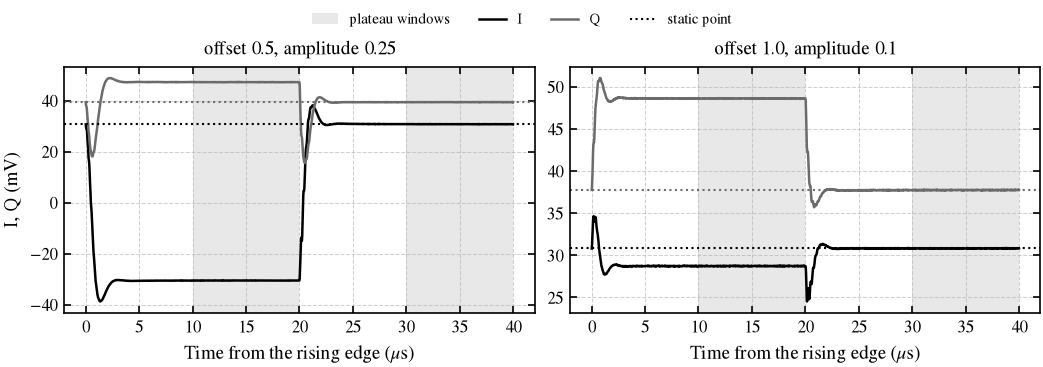

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.5))
for ax, (o, a) in zip(axes, EXAMPLES):
    z = meas[o, a]
    ax.axvspan((T / 2 - PLATEAU) * 1e6, T / 2 * 1e6, color=GRAY, alpha=0.15, lw=0, label="plateau windows")
    ax.axvspan((T - PLATEAU) * 1e6, T * 1e6, color=GRAY, alpha=0.15, lw=0)
    ax.plot(tb * 1e6, z.real * 1e3, color=MEASURED, label="I")
    ax.plot(tb * 1e6, z.imag * 1e3, color=GRAY, label="Q")
    ax.axhline(static_z[o].real * 1e3, color=MEASURED, ls=":", lw=1.0, label="static point")
    ax.axhline(static_z[o].imag * 1e3, color=GRAY, ls=":", lw=1.0)
    ax.set_title(f"offset {o}, amplitude {a}")
    ax.set_xlabel(r"Time from the rising edge ($\mu$s)")
    grid(ax)
axes[0].set_ylabel("I, Q (mV)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=4, fontsize=7)
save(fig, "07_folded_records", RESULTS / "figures")
plt.show()

Each panel is one record averaged over 5000 pulses. At the rising edge the trace leaves the static point of its offset
(dotted), after the falling edge at 20 $\mu$s it returns to it, and after each edge it needs two to three microseconds
to settle; the shaded windows are the plateaus used for the calibration in Step 4.

**How the folds were made** (`scripts/prepare_demo_data.py`, with the functions of `uc.analysis.pulses`):

* **Period** (`estimate_period`). The true period differs from 1600 samples by less than a thousandth of a sample,
  which still adds up to 3 samples over 5000 pulses and would smear every edge; it is measured from the phase drift of
  the first 20 harmonics of the pulse rate between the first and the last quarter of the record.
* **Fold** (`fold_pulses`). All pulses are averaged into 1600 bins of 25 ns.
* **Align** (`align_to_rising_edge`). A coarse edge is the best match to a $\pm 1$ square wave; it lands up to
  1.25 $\mu$s late, because the ring-up drags the match. Each edge is therefore placed at its *departure*
  (`departure_bin`): the last bin before the trace leaves the preceding plateau by more than the larger of 6 sigma of
  the plateau noise and 0.5% of the step. The two edges are exactly half a period apart, so the earlier detection is
  kept for both, and the rising edge is the one after which the trace moves *away* from the static point.

**Optional: refold one raw record.** The 40 raw records (27 MB each) are too large to ship. If you have them, set the
environment variable `UMUX_RAW_DATA` to the archive folder that contains `2026-10-04/` before starting Jupyter, or set
`RAW` in the cell to the folder of the records themselves. Without either, the cell looks in
`../../NIST_uMux_measurment_data`, where the archive sits next to the repository on the authors' machine (also the
default of `scripts/prepare_demo_data.py`), and if nothing is there it only says so. With the records it refolds the
first example and its static record from scratch and compares the result with the shipped fold.

In [4]:
RAW = Path(os.environ.get("UMUX_RAW_DATA", "../../NIST_uMux_measurment_data")) / "2026-10-04" / "good" / "IQ_pulse_data"
if RAW.exists():
    o, a = EXAMPLES[0]
    t0 = time.perf_counter()
    z_static = uc.load_record(next(RAW.glob(pulses.pulse_record_name(o, 0.0)))).z.mean()
    rec = uc.load_record(next(RAW.glob(pulses.pulse_record_name(o, a))))
    P_rec = pulses.estimate_period(rec.z, NBIN)
    refold = pulses.align_to_rising_edge(pulses.fold_pulses(rec.z, P_rec, NBIN), z_static, NBIN, N_PLAT)
    print(f"{Path(rec.path).name}: {len(rec.z)} samples at {rec.fs / 1e6:g} MS/s, logged rate {rec.rate / 1e3:g} kHz (wrong)")
    print(f"measured period {P_rec:.5f} samples = {P_rec / rec.fs * 1e6:.6f} us, {len(rec.z) / P_rec:.0f} pulses")
    print(f"largest difference from the shipped fold: {np.abs(refold - meas[o, a]).max():.1e} V "
          f"(refolded in {time.perf_counter() - t0:.1f} s)")
else:
    print(f"raw records not found in {RAW}; skipped")

IQ_0p5phi0_offset_0p25phi0amp_20261004_171433.npz: 8000000 samples at 40 MS/s, logged rate 50 kHz (wrong)
measured period 1600.00062 samples = 40.000015 us, 5000 pulses
largest difference from the shipped fold: 0.0e+00 V (refolded in 1.6 s)


## 2. The flux of every level, from the source

The flux of each plateau is measured, not fitted: the source output was recorded directly on the digitizer at offset
0.5 and amplitudes 0 to 1, and `source_levels.npz` holds the low and high level of each recording
(`pulses.source_levels`). From them `pulses.source_scales` gives the volts per unit of nominal amplitude $v_a$ (the
slope of the step height against the amplitude) and per unit of nominal offset $v_o$ (the mean low level above the
baseline $v_0$, the output with nothing playing, divided by the offset 0.5). The line current turns volts into flux,
$\Phi/\Phi_0 = v\,M_\mathrm{fr}/(\Phi_0 (R_\mathrm{loop} + R_\mathrm{src}))$ with $R_\mathrm{loop} = 1983\,\Omega$
(the two 1 k$\Omega$ series resistors and the coil loop, multimeter) and $R_\mathrm{src} = 50\,\Omega$ (assumed), so
that a record at nominal offset $o$ and amplitude $a$ steps between $\Phi_\mathrm{off} = k_o\,o + b$ and
$\Phi_\mathrm{on} = \Phi_\mathrm{off} + k_a\,a$.

In [5]:
levels = dict(np.load(PULSE_DIR / "source_levels.npz"))
device = uc.load_config(CONFIG)
ch = device[0]
Mfr = ch.line("FluxRamp").M

v_amp, v_off = pulses.source_scales(levels["lo"], levels["hi"], levels["v_zero"], levels["amps"], float(levels["offset"]))
v_zero = float(levels["v_zero"])
phi_per_V = pulses.flux_per_volt(Mfr, R_LOOP, R_SRC)
cal = pulses.LevelCalibration.from_source(levels, Mfr, R_LOOP, R_SRC)    # ka, ko, b = v_amp, v_off, v_zero times phi_per_V

print(f"source   v_a {v_amp * 1e3:6.1f} mV per unit amplitude, v_o {v_off * 1e3:6.1f} mV per unit offset, v_0 {v_zero * 1e3:+6.1f} mV")
print(f"line     Mfr {Mfr * 1e12:.2f} pH (10/04 configuration), R_loop + R_src = {R_LOOP + R_SRC:.0f} Ohm: {phi_per_V:.4f} Phi0 per V")
print(f"flux     ka {cal.ka:.4f}, ko {cal.ko:.4f} Phi0 per nominal unit, b {cal.b:+.4f} Phi0")
print(f"example  offset 0.5, amplitude 0.25 steps between {cal.flux(0.5, 0.0):.3f} and {cal.flux(0.5, 0.25):.3f} Phi0")

store.record("PulseKa", cal.ka, "{:.3f}", "flux per unit nominal pulse amplitude, Phi0, from the source records (07)")
store.record("PulseKo", cal.ko, "{:.3f}", "flux per unit nominal pulse offset, Phi0, from the source records (07)")
store.record("PulseBase", cal.b, "{:.3f}", "flux at zero nominal offset (source baseline), Phi0 (07)")
print("\nrecorded:", ", ".join(f"{name} {store.text(name)}" for name in ("PulseKa", "PulseKo", "PulseBase")))

source   v_a  299.7 mV per unit amplitude, v_o  273.0 mV per unit offset, v_0  -24.2 mV
line     Mfr 14.40 pH (10/04 configuration), R_loop + R_src = 2033 Ohm: 3.4253 Phi0 per V
flux     ka 1.0265, ko 0.9350 Phi0 per nominal unit, b -0.0828 Phi0
example  offset 0.5, amplitude 0.25 steps between 0.385 and 0.641 Phi0

recorded: PulseKa 1.027, PulseKo 0.935, PulseBase -0.083


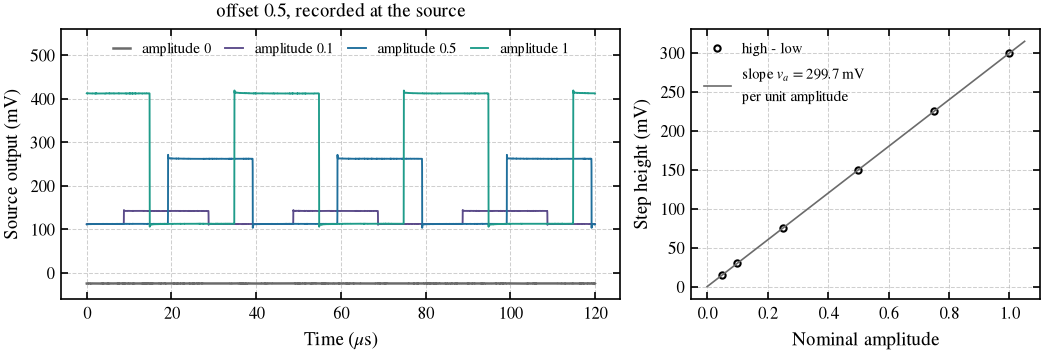

In [6]:
fs_src = float(levels["fs"])
t_src = np.arange(levels["excerpt"].shape[1]) / fs_src
amps_src = levels["amps"]
height = levels["hi"] - levels["lo"]

fig, (ax_t, ax_h) = plt.subplots(1, 2, figsize=(DOUBLE, 2.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax_t.plot(t_src * 1e6, levels["excerpt_zero"] * 1e3, color=GRAY, label="amplitude 0")
for a, x, color in zip(amps_src[1::2], levels["excerpt"][1::2], ORDERED_3):      # every other recorded amplitude
    ax_t.plot(t_src * 1e6, x * 1e3, color=color, lw=0.9, label=f"amplitude {a:g}")
ax_t.set_xlabel(r"Time ($\mu$s)")
ax_t.set_ylabel("Source output (mV)")
ax_t.set_title(f"offset {float(levels['offset']):g}, recorded at the source")
ax_t.set_ylim(-60, 560)
ax_t.legend(loc="upper center", fontsize=7, ncol=4, handlelength=1.2, columnspacing=1.0)
aa = np.linspace(0, 1.05, 2)
ax_h.plot(amps_src, height * 1e3, "o", color=MEASURED, mfc="none", label="high - low")
ax_h.plot(aa, (height.mean() + v_amp * (aa - amps_src.mean())) * 1e3, color=GRAY, lw=0.8,
          label=f"slope $v_a$ = {v_amp * 1e3:.1f} mV\nper unit amplitude")
ax_h.set_xlabel("Nominal amplitude")
ax_h.set_ylabel("Step height (mV)")
ax_h.legend(loc="upper left", fontsize=7)
for ax in (ax_t, ax_h):
    grid(ax)
save(fig, "07_source_levels", RESULTS / "figures")
plt.show()

Apart from a spike of one or two samples at each edge, the recorded output holds flat levels, and its step height is
linear in the nominal amplitude. Offset and amplitude are separate settings of the source and do not share a scale
($k_o \ne k_a$); an ideal voltage source ($R_\mathrm{src} = 0$) would raise both by 2.5%.

## 3. The virtual device at the probe tone

On the plateau windows, 10 to 20 $\mu$s after an edge, the field has long reached its steady state for the plateau
flux, so the plateau levels are given by the quasi-static response: $\dot a = 0$ in the equation of motion, with the
RF dressing at $E_r = |a|^2$ iterated to self-consistency (`uc.static_response`, tabulated once on a flux grid from
$-0.5$ to $2.5\,\Phi_0$). The device is the configuration extracted in notebook `01` from the VNA sweep of the same
day, taken 80 minutes before the pulse records; the bare frequency of the resonator moved by 0.38 MHz between 26 Sep
and 4 Oct, so only a same-day characterisation will do. Its $\lambda$ and $M_c$ were fitted to that sweep at
$-88$ dBm at the chip and so already contain the RF dressing at about the power of the pulse records; the model
dresses them again, a small double count whose effect Step 4 quantifies.

In [7]:
kc, kappa, alpha = ch.get_kappa_c(), ch.kappa, ch.alpha
tf = uc.FluxLineTF.from_file(POLES)
static = uc.static_response(device, F_PROBE, P_CHIP)          # quasi-static S21 against the ramp-line flux

print(device.summary())
print(f"\n{'probe tone':<26}{F_PROBE / 1e6:10.3f} MHz   ({(F_PROBE - ch.f0) / 1e3:+.0f} kHz from f0)")
print(f"{'probe power at the chip':<26}{P_CHIP:10.1f} dBm")
print(f"{'ring-up time 2/kappa':<26}{ch.ring_up_time * 1e9:10.0f} ns")
f_slow, _, tau_slow = max(tf.mode_table(), key=lambda m: m[2])       # the bias-line mode that decays slowest
print(f"{'slowest bias-line mode':<26}{tau_slow * 1e9:10.0f} ns   (1/e decay of the {f_slow / 1e6:.2f} MHz mode)")
print(f"{'plateau window starts':<26}{(T / 2 - PLATEAU) * 1e6:10.0f} us after an edge: "
      f"{(T / 2 - PLATEAU) / ch.ring_up_time:.0f} ring-up times, {(T / 2 - PLATEAU) / tau_slow:.0f} line decay times")

nist_res2_2026-10-04: 1 channel(s), Z0 = 50 Ohm
 ch   f0 (MHz)      Qr      Qc        Qi   alpha   lamb  Mc (pH)  BW (kHz)
  0   5515.305    9527   10464    106398  -0.089  0.316     3.70       579

probe tone                  5515.030 MHz   (-275 kHz from f0)
probe power at the chip        -88.9 dBm
ring-up time 2/kappa             550 ns
slowest bias-line mode           395 ns   (1/e decay of the 4.53 MHz mode)
plateau window starts             10 us after an edge: 18 ring-up times, 25 line decay times


## 4. Calibrating the IQ plane on the plateaus

As for the flux ramps (notebook `06`), the measurement model is $z = A\,S_{21}(\Phi) + B$, with $A$ the complex gain of
the readout chain and $B$ the demodulator's DC offset, fitted anew because the probe tone (0.77 MHz lower), the
demodulator phase and the gains differ from those of 26 Sep. The calibration points are 36 distinct plateau levels at
their source flux (`pulses.calibration_levels`): one off level per offset (its static point and the off plateaus of all
its records, averaged) and one on level per record. `pulses.fit_levels` fits $A$ and $B$, four real numbers on 72, by
linear least squares, and once more with each offset held out to predict that offset's levels; these are the only
parameters fitted to the plateaus, and apart from one common time shift per model (Step 6) nothing is fitted to the
edges. Residuals $|z_\mathrm{meas} - z_\mathrm{model}|$ are given in mV and relative to the diameter of the resonance
circle in the IQ plane, $|A|\,\kappa_c/(\kappa\cos\alpha)$ (`pulses.iq_circle_diameter`).

In [8]:
cal_off, cal_amp, cal_z, off_levels = pulses.calibration_levels(folds, OFFSETS, NBIN, N_PLAT)
cal_phi = cal.flux(cal_off, cal_amp)
s21_cal = static(cal_phi)
fit = pulses.fit_levels(s21_cal, cal_z, cal_off, OFFSETS)
A, B = fit.A, fit.B
z_fit = A * s21_cal + B                                # the model levels
held = fit.held_out_by_level                           # residual of each level with its offset held out
diam = pulses.iq_circle_diameter(A, kc, kappa, alpha)
cal_rms, held_rms = pulses.rms(fit.residual), pulses.rms(fit.held_out)
scatter = pulses.off_level_scatter(off_levels)

print(f"{'gain A':<22}|A| = {abs(A) * 1e3:.2f} mV, arg A = {np.angle(A):.3f} rad")
print(f"{'offset B':<22}{B.real * 1e3:+.2f} {B.imag * 1e3:+.2f}j mV")
print(f"{'circle diameter':<22}{diam * 1e3:.1f} mV")
print(f"{'residual':<22}rms {cal_rms * 1e3:.2f} mV ({cal_rms / diam:.2%} of the diameter), max {np.abs(fit.residual).max() * 1e3:.2f} mV")
print(f"{'held out':<22}rms {held_rms * 1e3:.2f} mV ({held_rms / diam:.2%}), one offset at a time")
print(f"{'off-level scatter':<22}rms {scatter * 1e3:.2f} mV within an offset")


def row(i):
    amp = "off" if cal_amp[i] == 0 else f"{cal_amp[i]:.2f}"
    return f"{cal_off[i]:6.2f} {amp:>5} {cal_phi[i]:7.3f} {abs(fit.residual[i]) * 1e3:6.2f} {abs(held[i]) * 1e3:6.2f}"


half = (len(cal_z) + 1) // 2
print(f"\n{'offset':>6} {'amp':>5} {'flux':>7} {'resid':>6} {'held':>6}      {'offset':>6} {'amp':>5} {'flux':>7} {'resid':>6} {'held':>6}")
for i in range(half):
    print(row(i) + ("      " + row(i + half) if i + half < len(cal_z) else ""))
print("(flux in Phi0, residuals in mV)")

store.record("PulseGainMag", abs(A) * 1e3, "{:.2f}", "readout gain |A| of the pulse records, mV (07)")
store.record("PulseGainArg", np.angle(A), "{:.3f}", "readout gain phase arg A of the pulse records, rad (07)")
store.record("PulseOffRe", B.real * 1e3, "{:.2f}", "demodulator offset Re B of the pulse records, mV (07)")
store.record("PulseOffIm", B.imag * 1e3, "{:.2f}", "demodulator offset Im B of the pulse records, mV (07)")
store.record("PulseNLevels", len(cal_z), "{:.0f}", "distinct plateau levels in the A, B fit (07)")
store.record("PulsePlateau", PLATEAU * 1e6, "{:.0f}", "plateau window at the end of each half period, us (07)")
store.record("PulseCalRms", cal_rms * 1e3, "{:.2f}", "rms residual of the plateau levels, mV (07)")
store.record("PulseCalRel", cal_rms / diam * 100, "{:.1f}", "rms residual of the plateau levels, % of the circle diameter (07)")
store.record("PulseCalHeld", held_rms * 1e3, "{:.2f}", "rms held-out residual of the plateau levels, one offset at a time, mV (07)")
store.record("PulseLevelScatter", scatter * 1e3, "{:.2f}", "rms spread of the off levels within an offset, mV (07)")
print("\nrecorded:", ", ".join(f"{name} {store.text(name)}" for name in (
    "PulseGainMag", "PulseGainArg", "PulseOffRe", "PulseOffIm", "PulseNLevels", "PulseCalRms", "PulseCalRel", "PulseCalHeld",
    "PulseLevelScatter")))

gain A                |A| = 69.15 mV, arg A = 1.492 rad
offset B              -0.70 -0.72j mV
circle diameter       63.2 mV
residual              rms 0.62 mV (0.99% of the diameter), max 1.94 mV
held out              rms 0.73 mV (1.16%), one offset at a time
off-level scatter     rms 0.07 mV within an offset

offset   amp    flux  resid   held      offset   amp    flux  resid   held
  0.00   off  -0.083   0.22   0.29        0.50  0.10   0.487   1.94   2.20
  0.25   off   0.151   0.51   0.58        0.50  0.25   0.641   0.42   0.47
  0.50   off   0.385   0.51   0.67        0.50  0.50   0.898   0.17   0.02
  0.75   off   0.618   0.31   0.51        0.50  1.00   1.411   0.55   0.72
  1.00   off   0.852   0.36   0.39        0.50  1.20   1.617   0.38   0.45
  0.00  0.05  -0.032   0.33   0.41        0.75  0.05   0.670   0.61   1.03
  0.00  0.10   0.020   0.43   0.51        0.75  0.10   0.721   1.61   1.97
  0.00  0.25   0.174   0.59   0.68        0.75  0.25   0.875   0.19   0.19
  0.00  0.50  

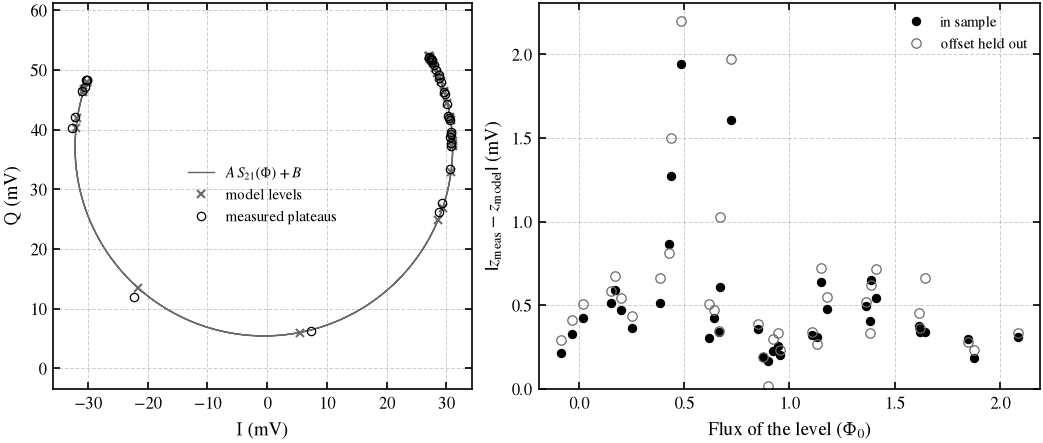

In [9]:
phi = np.linspace(0, 1, 1001)                         # one flux quantum traces the curve (out and back)
z_curve = A * static(phi) + B

fig, (ax_iq, ax_r) = plt.subplots(1, 2, figsize=(DOUBLE, 3.0), gridspec_kw={"width_ratios": [1, 1.2]})
ax_iq.plot(z_curve.real * 1e3, z_curve.imag * 1e3, color=GRAY, lw=0.7, label=r"$A\,S_{21}(\Phi) + B$")
ax_iq.plot(z_fit.real * 1e3, z_fit.imag * 1e3, "x", color=GRAY, ms=4, label="model levels")
ax_iq.plot(cal_z.real * 1e3, cal_z.imag * 1e3, "o", color=MEASURED, mfc="none", ms=4, mew=0.6, label="measured plateaus")
ax_iq.set_aspect("equal", "datalim")
ax_iq.set_xlabel("I (mV)")
ax_iq.set_ylabel("Q (mV)")
ax_iq.legend(loc="center", fontsize=7)
ax_r.plot(cal_phi, np.abs(fit.residual) * 1e3, "o", color=MEASURED, ms=3.5, label="in sample")
ax_r.plot(cal_phi, np.abs(held) * 1e3, "o", color=GRAY, mfc="none", ms=4.5, mew=0.6, label="offset held out")
ax_r.set_xlabel(r"Flux of the level ($\Phi_0$)")
ax_r.set_ylabel(r"$|z_\mathrm{meas} - z_\mathrm{model}|$ (mV)")
ax_r.set_ylim(bottom=0)
ax_r.legend(loc="upper right", fontsize=7)
for ax in (ax_iq, ax_r):
    grid(ax)
save(fig, "07_plateau_calibration", RESULTS / "figures")
plt.show()

The 36 levels lie on the circle where their source flux puts them, to 1% of its diameter, and the held-out residuals
are barely larger than the in-sample ones, so the four fitted numbers do not carry the agreement. The off levels of one
offset agree with each other to 0.07 mV (`pulses.off_level_scatter`), almost ten times better than the fit, so the
remaining misfit is a static error of the model at this probe tone, not drift. It is largest where the response is
steepest: the two worst levels (0.49 and 0.72 $\Phi_0$) sit where 0.002 $\Phi_0$ of flux moves $z$ by 1.6 mV, eight
times the median slope of the levels. Part of it is the double dressing of Step 3: with the static response tabulated
without the RF dressing (`n_iter=1` in `uc.static_response`, i.e. $E_r = 0$), the same fit leaves 0.44 mV rms instead
of 0.62 mV, and 1.00 mV instead of 1.94 mV at the worst level. The paper and this notebook keep the dressed model, the
same one that drives the simulations.

## 5. Simulating every record

Each record is driven by the square wave between its calibrated off and on fluxes (`uc.signals.square`, rising edge
at $t = 0$), either as is (the ideal square) or through the bias line: `tf.apply_periodic` multiplies every harmonic of
the periodic drive by $H(f)$, and since $H(0) = 1$ the plateau fluxes pass unchanged. `uc.simulate` integrates the
equation of motion with the RF dressing at the instantaneous stored energy, from the static steady state 5 $\mu$s
before the rising edge (on the off plateau, 15 $\mu$s after the previous falling edge), and returns one period at
5 ns, with internal steps of at most 20 ns so that the 4.5 MHz ringing is resolved. The 62 runs (31 records, two
drives) take about 20 s.

In [10]:
t_sim = np.arange(int(round(T / 5e-9))) * 5e-9        # one period at 5 ns, rising edge at t = 0
DRIVES = {"ideal": (False, MODEL_IDEAL, "ideal square"), "tf": (True, MODEL_TF, "through $H(f)$")}


def flux_drive(o, a, use_tf):
    "Flux on the ramp line (Phi0) against time for the record at nominal offset o and amplitude a."
    source = uc.signals.square(T, cal.flux(o, 0.0), cal.flux(o, a))
    return tf.apply_periodic(source, T) if use_tf else source


def simulate(o, a, use_tf):
    I_coil = uc.signals.flux_to_current(flux_drive(o, a, use_tf), Mfr, uc.Phi0)
    return uc.simulate(device, F_PROBE, P_CHIP, t_sim, flux_ramp_current_func=I_coil, settle=5e-6, max_step=20e-9)


t0 = time.perf_counter()
sims = {}                                             # periodic interpolants of S21(t), by (record, drive)
for k in meas:
    for kind, (use_tf, _, _) in DRIVES.items():
        res = simulate(*k, use_tf)
        sims[k, kind] = uc.periodic_interpolant(res.t, res.s21, T)
t_step5 = time.perf_counter() - t0
print(f"{len(sims)} simulations of {(5e-6 + T) * 1e6:.0f} us each in {t_step5:.1f} s")

62 simulations of 45 us each in 20.0 s


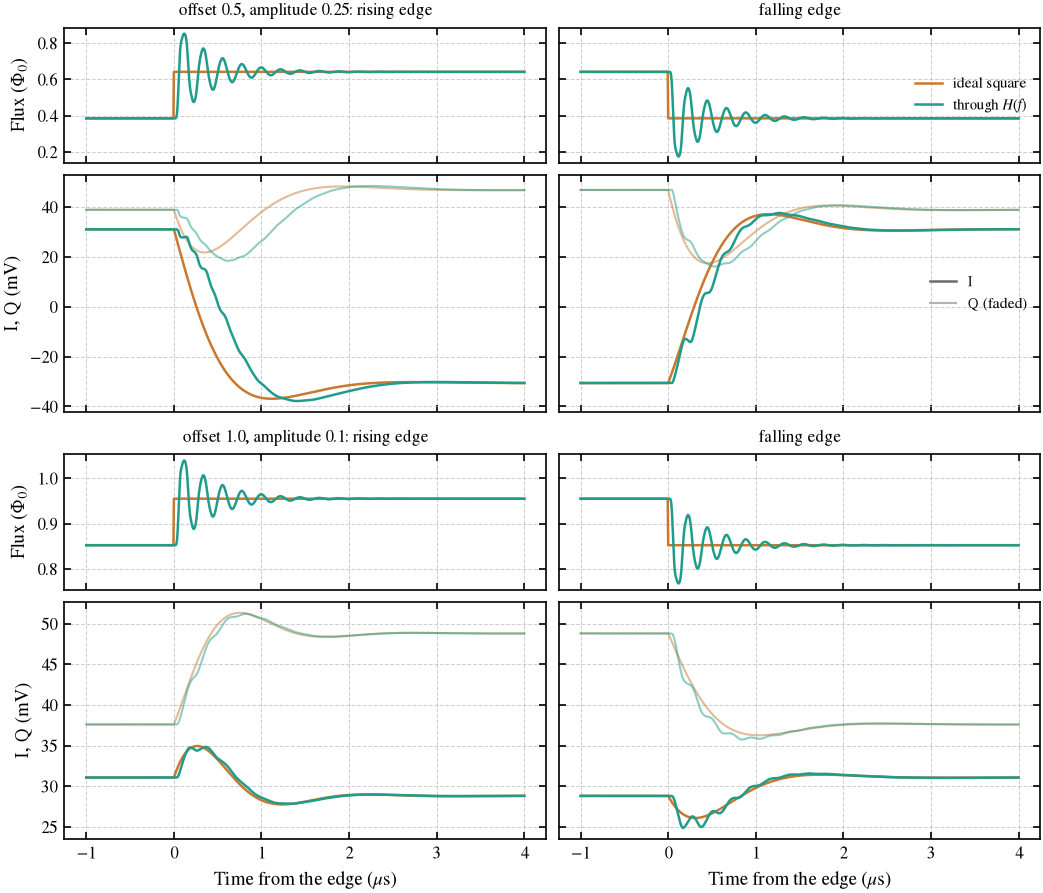

In [11]:
EDGES = [(0.0, "rising edge"), (T / 2, "falling edge")]
tt = np.linspace(-1e-6, 4e-6, 1001)                   # time from the edge

fig, axes = plt.subplots(4, 2, figsize=(DOUBLE, 6), sharex=True, sharey="row",
                         gridspec_kw={"height_ratios": [0.8, 1.4, 0.8, 1.4]})
for rows_, (o, a) in zip((axes[:2], axes[2:]), EXAMPLES):
    for j, (edge, name) in enumerate(EDGES):
        for kind, (use_tf, color, label) in DRIVES.items():
            z = A * sims[(o, a), kind](tt + edge) + B
            rows_[0, j].plot(tt * 1e6, flux_drive(o, a, use_tf)(tt + edge), color=color, label=label)
            rows_[1, j].plot(tt * 1e6, z.imag * 1e3, color=color, lw=1.0, alpha=0.5)
            rows_[1, j].plot(tt * 1e6, z.real * 1e3, color=color)
    rows_[0, 0].set_ylabel(r"Flux ($\Phi_0$)")
    rows_[1, 0].set_ylabel("I, Q (mV)")
    rows_[0, 0].set_title(f"offset {o}, amplitude {a}: rising edge", fontsize=8)
    rows_[0, 1].set_title("falling edge", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel(r"Time from the edge ($\mu$s)")
axes[0, 1].legend(loc="center right", fontsize=7)
axes[1, 1].plot([], [], color=GRAY, label="I")
axes[1, 1].plot([], [], color=GRAY, alpha=0.5, lw=1.0, label="Q (faded)")
axes[1, 1].legend(loc="center right", fontsize=7)
for ax in axes.flat:
    grid(ax)
save(fig, "07_simulated_edges", RESULTS / "figures")
plt.show()

Through $H(f)$ the coil flux overshoots each step by about 80% and rings at 4.5 MHz for about a microsecond and a
half. The resonator, with its 580 kHz bandwidth, smooths most of that ringing away but not all of it: the simulated $I$
and $Q$ carry a 4.5 MHz ripple for about a microsecond, and on the rising edge of the large step the whole transition
is a few hundred nanoseconds slower than with the ideal square. The slow swing past the new plateau, after every edge
and with both drives, is the field spiralling into its new steady state: it turns at the new detuning of the probe from
the resonance (about 340 to 520 kHz here) while it decays at $\kappa/2$.

## 6. Comparison with the measured edges (Fig. 11)

Every simulated record is mapped into volts with the plateau $A$ and $B$ and compared with its fold over the edge
windows, the first 3 $\mu$s after each edge (about 5 ring-up times); nothing is refitted. A measured bin averages a
25 ns slice of the period, so the model is averaged over the same slices (`pulses.binned_model`, 5 sub-samples per
bin), and one time shift common to all 31 records slides each model in time, because bin 0 of a fold is a point defined
by the data (its departure bin) and the readout delays the trace (cables, the digitizer's anti-alias filter). The shift
minimises the squared residual summed over the edge windows of all records (`pulses.fit_edge_shift`: $-300$ to 300 ns
in 5 ns steps, then refined in 0.25 ns steps); each model gets its own, and the ideal square is also scored at the
$H(f)$ shift, the shared readout delay. Residuals are the rms of $|z_\mathrm{meas} - z_\mathrm{model}|$ over the edge
windows of each record (`pulses.edge_rms`), in mV and relative to the record's step $|z_\mathrm{on} - z_\mathrm{off}|$.

In [12]:
EDGE_KW = dict(nbin=NBIN, period=T, edge=pulses.EDGE, sub=pulses.SUB)   # 3 us windows after each edge, 5 sub-samples per bin
keys = list(meas)
zs = [meas[k] for k in keys]


def binned(model, shift):
    "The model in volts at the measured bins: shifted by `shift` and averaged over each 25 ns bin."
    return A * pulses.binned_model(model, shift, NBIN, T, pulses.SUB) + B


def edge_residuals(kind, shift):
    "rms residual over the edge windows of each record, for one model."
    return np.array([pulses.edge_rms(meas[k], sims[k, kind], A, B, shift, **EDGE_KW) for k in keys])


t0 = time.perf_counter()
SHIFT, sq = {}, {}
for kind in DRIVES:
    models = [sims[k, kind] for k in keys]
    SHIFT[kind] = pulses.fit_edge_shift(zs, models, A, B, **EDGE_KW)
    sq[kind] = pulses.edge_residual_sum(zs, models, A, B, SHIFT[kind], **EDGE_KW)
for kind, (_, _, label) in DRIVES.items():
    print(f"{label.replace('$', ''):15s} shift {SHIFT[kind] * 1e9:+6.1f} ns, summed squared residual {sq[kind] * 1e6:9.1f} mV^2")
print(f"(scans in {time.perf_counter() - t0:.1f} s)")

step_ = np.array([abs(step[k]) for k in keys])
noise_ = np.array([noise[k] for k in keys])
err_tf, err_id = edge_residuals("tf", SHIFT["tf"]), edge_residuals("ideal", SHIFT["ideal"])
err_ic = edge_residuals("ideal", SHIFT["tf"])         # the ideal square at the H(f) shift
ratio_c = pulses.edge_residual_sum(zs, [sims[k, "ideal"] for k in keys], A, B, SHIFT["tf"], **EDGE_KW) / sq["tf"]

print(f"\n{'offset':>6} {'amp':>5} {'step':>7} {'noise':>6}   {'H(f)':>6} {'/step':>6}   {'ideal':>6} {'/step':>7}   (mV)")
for (o, a), st, n, et, ei in zip(keys, step_, noise_, err_tf, err_id):
    print(f"{o:6.2f} {a:5.2f} {st * 1e3:7.2f} {n * 1e3:6.3f}   {et * 1e3:6.2f} {et / st:6.1%}   {ei * 1e3:6.2f} {ei / st:7.1%}")

big = step_ >= 10e-3
print(f"\nrecords with a step of at least 10 mV ({big.sum()}): residual / step median {np.median(err_tf[big] / step_[big]):.1%} "
      f"through H(f) (max {np.max(err_tf[big] / step_[big]):.1%}), {np.median(err_id[big] / step_[big]):.1%} ideal")
print(f"all records: rms residual {pulses.rms(err_tf) * 1e3:.2f} mV through H(f), {pulses.rms(err_id) * 1e3:.2f} mV ideal; "
      f"noise per bin median {np.median(noise_) * 1e3:.3f} mV")
print(f"ideal square at the H(f) shift: summed squared residual {ratio_c:.0f} times that of H(f), "
      f"median residual / step {np.median(err_ic[big] / step_[big]):.1%} for the large steps")

store.record("PulseShift", SHIFT["tf"] * 1e9, "{:.0f}", "time shift common to all records, H(f) model, ns (07)")
store.record("PulseShiftIdeal", SHIFT["ideal"] * 1e9, "{:.0f}", "time shift common to all records, ideal-square model, ns (07)")
store.record("PulseRatio", sq["ideal"] / sq["tf"], "{:.0f}", "summed squared edge residual, ideal square over H(f), each at its own shift (07)")
store.record("PulseRatioCommon", ratio_c, "{:.0f}", "the same ratio with the ideal square at the H(f) shift (07)")
store.record("PulseNBig", big.sum(), "{:.0f}", "records with a step of at least 10 mV (07)")
store.record("PulseEdgeMed", 100 * np.median(err_tf[big] / step_[big]), "{:.1f}", "median edge residual / step, H(f), steps >= 10 mV, % (07)")
store.record("PulseEdgeMax", 100 * np.max(err_tf[big] / step_[big]), "{:.1f}", "largest edge residual / step, H(f), steps >= 10 mV, % (07)")
store.record("PulseIdealMed", 100 * np.median(err_id[big] / step_[big]), "{:.0f}", "median edge residual / step, ideal square, steps >= 10 mV, % (07)")
store.record("PulseIdealMedCommon", 100 * np.median(err_ic[big] / step_[big]), "{:.0f}", "the same at the H(f) shift, % (07)")
store.record("PulseRms", pulses.rms(err_tf) * 1e3, "{:.2f}", "rms edge residual over all records, H(f), mV (07)")
store.record("PulseRmsIdeal", pulses.rms(err_id) * 1e3, "{:.1f}", "rms edge residual over all records, ideal square, mV (07)")
store.record("PulseNoise", np.median(noise_) * 1e3, "{:.3f}", "median noise per 25 ns bin of the folded records, mV (07)")
print("\nrecorded:", ", ".join(f"{name} {store.text(name)}" for name in (
    "PulseShift", "PulseShiftIdeal", "PulseRatio", "PulseRatioCommon", "PulseNBig", "PulseEdgeMed", "PulseEdgeMax",
    "PulseIdealMed", "PulseIdealMedCommon", "PulseRms", "PulseRmsIdeal", "PulseNoise")))

ideal square    shift +246.0 ns, summed squared residual  776121.0 mV^2
through H(f)    shift  -13.2 ns, summed squared residual    7374.6 mV^2
(scans in 2.4 s)

offset   amp    step  noise     H(f)  /step    ideal   /step   (mV)
  0.00  0.05    3.30  0.027     0.29   8.8%     0.98   29.8%
  0.00  0.10    5.15  0.027     0.37   7.2%     1.59   30.8%
  0.00  0.25    6.05  0.027     0.68  11.3%     3.03   50.1%
  0.00  0.50   18.27  0.028     1.05   5.7%     5.07   27.8%
  0.00  1.00    1.92  0.027     1.09  56.9%     8.96  467.3%
  0.00  1.20    6.20  0.027     1.07  17.3%    10.02  161.5%
  0.25  0.05    0.67  0.025     0.50  74.9%     0.56   84.0%
  0.25  0.10    2.06  0.027     0.48  23.5%     0.89   43.1%
  0.25  0.50   60.23  0.029     1.34   2.2%     7.26   12.1%
  0.25  0.75    5.95  0.026     1.33  22.3%     9.61  161.5%
  0.25  1.00    0.28  0.026     1.00 358.9%    10.50 3760.3%
  0.25  1.20   12.83  0.027     0.91   7.1%     9.44   73.5%
  0.50  0.05   13.38  0.029     0.98  

The two examples in the style of Fig. 11: the flux at the SQUID for both drives (top), the measured $I$ (black) and
$Q$ (gray) with both models (middle), and the measured minus the $H(f)$ model (bottom), all at the $H(f)$ shift. Each
pair of columns is one record, its rising and falling edge.

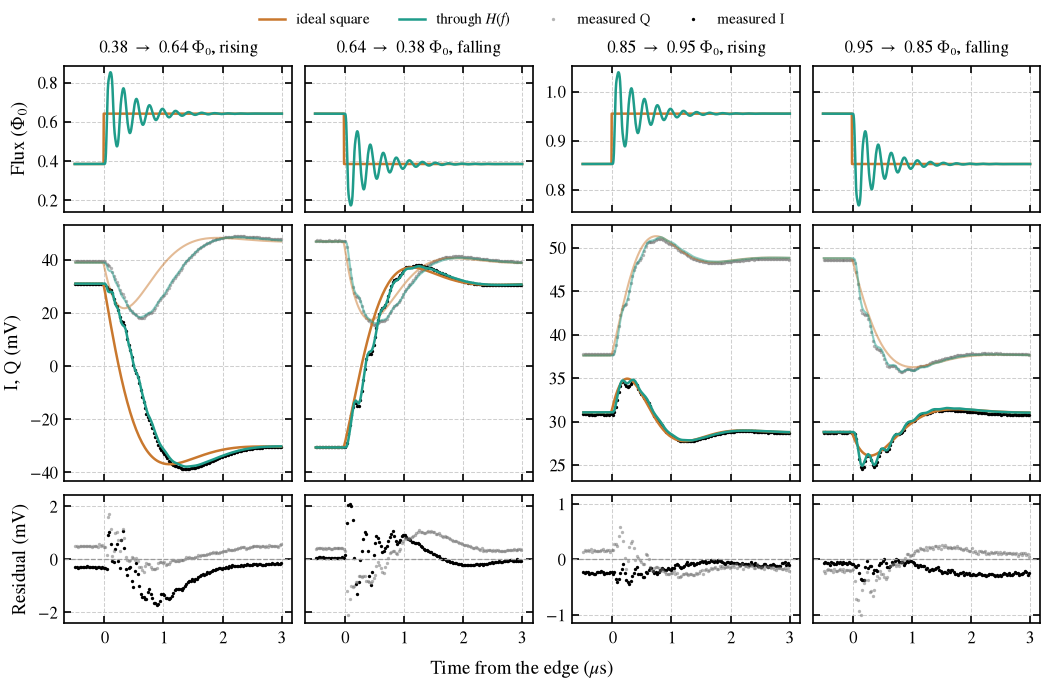

In [13]:
WIN = (-0.5e-6, 3e-6)
tt = np.linspace(*WIN, 2000)
dots = dict(ls="none", marker="o", ms=1.6, mew=0, zorder=2)

fig, axes = plt.subplots(3, 4, figsize=(DOUBLE, 4.6), sharex=True, gridspec_kw={"height_ratios": [0.8, 1.4, 0.7]})
for p in range(2):                                    # the two edges of one record share their y axes
    for r_ in range(3):
        axes[r_, 2 * p + 1].sharey(axes[r_, 2 * p])
        axes[r_, 2 * p + 1].tick_params(labelleft=False)
for p, (o, a) in enumerate(EXAMPLES):
    z, z_tf = meas[o, a], binned(sims[(o, a), "tf"], SHIFT["tf"])
    lo, hi = cal.flux(o, 0.0), cal.flux(o, a)
    lim = 0.0
    for e, (edge, name) in enumerate(EDGES):
        col = axes[:, 2 * p + e]
        tm = (tb - edge + T / 4) % T - T / 4          # time of each bin from this edge
        win = (tm > WIN[0]) & (tm < WIN[1])
        order = np.argsort(tm[win])
        x = tm[win][order] * 1e6
        for kind, (use_tf, color, label) in DRIVES.items():
            col[0].plot(tt * 1e6, flux_drive(o, a, use_tf)(tt + edge - SHIFT["tf"]), color=color, label=label)
            zs_ = binned(sims[(o, a), kind], SHIFT["tf"])[win][order]
            col[1].plot(x, zs_.imag * 1e3, color=color, lw=1.0, alpha=0.5, zorder=3)
            col[1].plot(x, zs_.real * 1e3, color=color, zorder=3)
        col[1].plot(x, z[win][order].imag * 1e3, color=GRAY, alpha=0.5, label="measured Q", **dots)
        col[1].plot(x, z[win][order].real * 1e3, color=MEASURED, label="measured I", **dots)
        r = (z - z_tf)[win][order]
        col[2].plot(x, r.real * 1e3, color=MEASURED, **dots)
        col[2].plot(x, r.imag * 1e3, color=GRAY, alpha=0.5, **dots)
        col[2].axhline(0, color=ZERO, ls="--", lw=0.6)
        lim = max(lim, 1.15 * np.abs(np.r_[r.real, r.imag]).max() * 1e3)
        f0_, f1_ = (lo, hi) if e == 0 else (hi, lo)
        col[0].set_title(rf"{f0_:.2f} $\to$ {f1_:.2f} $\Phi_0$, {name.split()[0]}", fontsize=8)
    axes[2, 2 * p].set_ylim(-lim, lim)
for ax in axes.flat:
    grid(ax)
axes[0, 0].set_ylabel(r"Flux ($\Phi_0$)")
axes[1, 0].set_ylabel("I, Q (mV)")
axes[2, 0].set_ylabel("Residual (mV)")
fig.supxlabel(r"Time from the edge ($\mu$s)", fontsize=9)
handles = [h for ax in axes[:2, 0] for h in zip(*ax.get_legend_handles_labels())]
fig.legend(*zip(*handles), loc="outside upper center", ncol=4, fontsize=7)
save(fig, "07_pulse_edges", RESULTS / "figures")
plt.show()

With the bias line in the model, the 4.5 MHz ripple and the timing of the measured transitions are reproduced at both
edges of both records. What is left is about 1 mV rms on the 62 mV step and 0.3 mV on the 11 mV one, and part of it is
the static misfit of the plateaus, already there before the edge. The ideal square misses the ripple, and on the large
step its transition comes too early; even at its own best shift it leaves a summed squared residual about a hundred
times larger. That best shift, a quarter of a microsecond, is far longer than any delay of the line or the readout: it
is the compromise of a model that cannot match the shape of the transient. The $H(f)$ model needs $-13$ ns, about half
a bin.

## 7. How much of the transient does the model explain?

A residual relative to the step blows up for the small steps: at amplitudes near $1\,\Phi_0$ the on and off levels are
almost the same IQ point, although the flux sweeps through a whole flux quantum at each edge. The breakdown below
therefore uses the circle diameter, a scale fixed for all records, over the same edge windows:

* **noise**: per 25 ns bin of the 5000-pulse average (the scatter about the plateau means);
* **plateau**: the static misfit of the record's own on and off levels, the floor the model cannot go below on the edges;
* **H(f)**, **ideal**: the CMT through $H(f)$ and with the ideal square, each at its own shift;
* **static**: the steady-state $S_{21}$ jumping instantly between the two plateau levels, at its own best shift
  (`pulses.fit_edge_shift` from $-0.3$ to 1 $\mu$s in 5 ns steps). This is the size of the transient, everything the
  measurement does that a static model misses;
* **H(f)/static**: the fraction of the transient the full model leaves unexplained. It is summarised over the records
  whose transient is at least 5 times their plateau misfit; below that the ratio measures the misfit, not the dynamics.

In [14]:
for k in keys:
    sims[k, "static"] = lambda q, square=uc.signals.square(T, cal.flux(k[0], 0.0), cal.flux(*k)): static(square(q))

t0 = time.perf_counter()
SHIFT["static"] = pulses.fit_edge_shift(zs, [sims[k, "static"] for k in keys], A, B, coarse=(-0.3e-6, 1.0e-6, 5e-9),
                                        fine=None, **EDGE_KW)
print(f"static model shift {SHIFT['static'] * 1e9:+.0f} ns (scan in {time.perf_counter() - t0:.1f} s)")

err_st = edge_residuals("static", SHIFT["static"])
floor_ = np.array([pulses.rms(np.subtract(on_off[k], pulses.plateau_levels(binned(sims[k, "tf"], SHIFT["tf"]), NBIN, N_PLAT)))
                   for k in keys])
frac = err_tf / err_st
clear = err_st >= 5 * floor_                          # transient well above the plateau misfit

print(f"\n{'offset':>6} {'amp':>5} {'step':>6} {'noise':>6} {'plateau':>8} {'H(f)':>6} {'ideal':>6} {'static':>7} {'H(f)/static':>12}")
for (o, a), st, n, fl, et, ei, es, c in zip(keys, step_, noise_, floor_, err_tf, err_id, err_st, clear):
    print(f"{o:6.2f} {a:5.2f} {st / diam:6.1%} {n / diam:6.2%} {fl / diam:8.2%} {et / diam:6.1%} {ei / diam:6.1%} "
          f"{es / diam:7.1%} {et / es:11.0%}{'' if c else ' *'}")
print(f"(all relative to the circle diameter, {diam * 1e3:.1f} mV; * transient < 5x the plateau misfit)\n")

subsets = [("all records", np.ones(len(keys), bool)), ("transient >= 5x plateau", clear), ("step >= 10 mV", big)]
print(f"{'':>24} {'n':>3} {'H(f) med':>9} {'max':>6} {'plateau':>8} {'static':>7} {'ideal':>6} {'H(f)/static med':>16} {'range':>10}")
for name, m in subsets:
    print(f"{name:>24} {m.sum():3d} {np.median(err_tf[m]) / diam:9.1%} {err_tf[m].max() / diam:6.1%} {np.median(floor_[m]) / diam:8.1%} "
          f"{np.median(err_st[m]) / diam:7.1%} {np.median(err_id[m]) / diam:6.1%} {np.median(frac[m]):16.0%} "
          f"{frac[m].min():5.0%}-{frac[m].max():.0%}")
print(f"noise per bin, median {np.median(noise_) / diam:.2%} of the diameter")

store.record("PulseResRel", 100 * np.median(err_tf) / diam, "{:.1f}", "median edge residual, H(f), all records, % of the circle diameter (07)")
store.record("PulseResRelMax", 100 * err_tf.max() / diam, "{:.1f}", "largest edge residual, H(f), % of the circle diameter (07)")
store.record("PulseFloorRel", 100 * np.median(floor_) / diam, "{:.1f}", "median plateau misfit of the records, % of the circle diameter (07)")
store.record("PulseStaticRel", 100 * np.median(err_st) / diam, "{:.0f}", "median edge residual of the static model, % of the circle diameter (07)")
store.record("PulseIdealRel", 100 * np.median(err_id) / diam, "{:.0f}", "median edge residual, ideal square, % of the circle diameter (07)")
store.record("PulseNoiseRel", 100 * np.median(noise_) / diam, "{:.2f}", "median noise per bin, % of the circle diameter (07)")
store.record("PulseNClear", clear.sum(), "{:.0f}", "records whose transient is at least 5x their plateau misfit (07)")
store.record("PulseUnexplainedMed", 100 * np.median(frac[clear]), "{:.0f}", "median H(f) / static edge residual over those records, % (07)")
store.record("PulseExplainedMed", 100 - 100 * np.median(frac[clear]), "{:.0f}", "100 minus PulseUnexplainedMed, % (07)")
store.record("PulseUnexplainedMin", 100 * frac[clear].min(), "{:.0f}", "smallest H(f) / static ratio over those records, % (07)")
store.record("PulseUnexplainedMax", 100 * frac[clear].max(), "{:.0f}", "largest H(f) / static ratio over those records, % (07)")
print("\nrecorded:", ", ".join(f"{name} {store.text(name)}" for name in (
    "PulseResRel", "PulseResRelMax", "PulseFloorRel", "PulseStaticRel", "PulseIdealRel", "PulseNoiseRel", "PulseNClear",
    "PulseUnexplainedMed", "PulseExplainedMed", "PulseUnexplainedMin", "PulseUnexplainedMax")))

static model shift +515 ns (scan in 1.5 s)

offset   amp   step  noise  plateau   H(f)  ideal  static  H(f)/static
  0.00  0.05   5.2%  0.04%    0.43%   0.5%   1.6%    1.9%         24% *
  0.00  0.10   8.2%  0.04%    0.53%   0.6%   2.5%    3.1%         19%
  0.00  0.25   9.6%  0.04%    0.73%   1.1%   4.8%    5.3%         20%
  0.00  0.50  28.9%  0.04%    1.01%   1.7%   8.0%    9.5%         17%
  0.00  1.00   3.0%  0.04%    0.34%   1.7%  14.2%   14.1%         12%
  0.00  1.20   9.8%  0.04%    0.76%   1.7%  15.8%   15.6%         11%
  0.25  0.05   1.1%  0.04%    0.78%   0.8%   0.9%    0.9%         87% *
  0.25  0.10   3.3%  0.04%    0.73%   0.8%   1.4%    1.6%         49% *
  0.25  0.50  95.3%  0.05%    0.71%   2.1%  11.5%   28.1%          8%
  0.25  0.75   9.4%  0.04%    0.68%   2.1%  15.2%   15.2%         14%
  0.25  1.00   0.4%  0.04%    0.75%   1.6%  16.6%   16.6%         10%
  0.25  1.20  20.3%  0.04%    0.69%   1.4%  14.9%   14.2%         10%
  0.50  0.05  21.2%  0.05%    1.55%   1

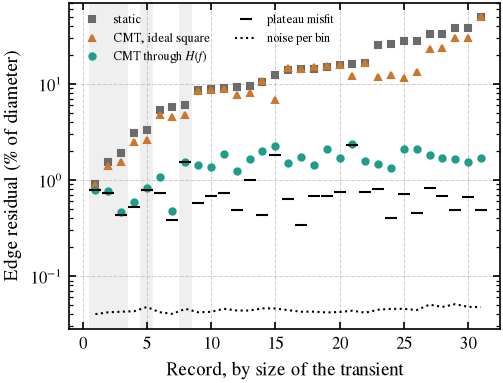

In [15]:
order = np.argsort(err_st)
n = np.arange(1, len(keys) + 1)

fig, ax = plt.subplots(figsize=(SINGLE, 2.6))
ax.semilogy(n, 100 * err_st[order] / diam, "s", color=GRAY, ms=3, label="static")
ax.semilogy(n, 100 * err_id[order] / diam, "^", color=MODEL_IDEAL, ms=3, label="CMT, ideal square")
ax.semilogy(n, 100 * err_tf[order] / diam, "o", color=MODEL_TF, ms=3, label="CMT through $H(f)$")
ax.semilogy(n, 100 * floor_[order] / diam, "_", color=MEASURED, ms=6, mew=1.0, label="plateau misfit")
ax.semilogy(n, 100 * noise_[order] / diam, ":", color=MEASURED, lw=1.0, label="noise per bin")
for i in np.flatnonzero(~clear[order]):
    ax.axvspan(n[i] - 0.5, n[i] + 0.5, color=GRAY, alpha=0.1, lw=0)
ax.set_xlabel("Record, by size of the transient")
ax.set_ylabel("Edge residual (% of diameter)")
ax.legend(loc="upper left", fontsize=6, ncol=2)
grid(ax)
save(fig, "07_residual_breakdown", RESULTS / "figures")
plt.show()

Over all 31 records the full model leaves a median of 1.6% of the circle diameter on the edges (at most 2.4%), against
14% for the static model. The plateau misfit alone, which the edges inherit, is a median of 0.7%, and the noise is more
than ten times smaller still. Of the transient itself, the model leaves a median of 11% unexplained over the 26 records
whose transient stands clear of their plateau misfit (the shaded records are the other five). Driving the CMT with the
ideal square instead does only a little better than the static model (median 11% against 14%): without the bias line,
the resonator dynamics alone leave most of the transient unexplained.

## 8. Run time

`simulate` for the two example records, with the ideal square and through $H(f)$: 45 $\mu$s of simulated time each
(5 $\mu$s of settling and one period) in steps of at most 20 ns. Each case is timed as the median of up to five runs,
and a CPU time equal to the wall time shows that a run uses a single core; the numbers depend on the machine and its
load (the paper quotes 0.36 s through $H(f)$ and 0.29 s with the ideal square). This cell takes about 7 s.

In [16]:
def run_time(fn, max_repeat=5, min_total=3.0):
    "Median wall and CPU time of fn() in s, over up to max_repeat runs or until min_total seconds of wall time."
    wall, cpu = [], []
    while len(wall) < max_repeat and sum(wall) < min_total:
        t0, c0 = time.perf_counter(), time.process_time()
        fn()
        wall.append(time.perf_counter() - t0)
        cpu.append(time.process_time() - c0)
    return float(np.median(wall)), float(np.median(cpu))


t_cell = time.perf_counter()
timing = {(k, kind): run_time(lambda: simulate(*k, use_tf)) for k in EXAMPLES for kind, (use_tf, _, _) in DRIVES.items()}
print(f"{'offset':>6} {'amp':>5} {'ideal (s)':>10} {'H(f) (s)':>9}   CPU/wall")
for k in EXAMPLES:
    (w_id, c_id), (w_tf, c_tf) = timing[k, "ideal"], timing[k, "tf"]
    print(f"{k[0]:6.2f} {k[1]:5.2f} {w_id:10.2f} {w_tf:9.2f}   {c_id / w_id:.2f} {c_tf / w_tf:.2f}")
per = {kind: np.mean([timing[k, kind][0] for k in EXAMPLES]) for kind in DRIVES}
print(f"all {len(meas)} records with both drives: about {len(meas) * (per['ideal'] + per['tf']):.0f} s "
      f"(Step 5 took {t_step5:.0f} s); this cell took {time.perf_counter() - t_cell:.1f} s")

store.record("PulseTimeTF", per["tf"], "{:.2f}", "wall time of one pulse record through H(f), s (07)")
store.record("PulseTimeIdeal", per["ideal"], "{:.2f}", "wall time of one pulse record with the ideal square, s (07)")
store.record("PulseTimeAll", len(meas) * (per["ideal"] + per["tf"]), "{:.0f}", "wall time of all records with both drives, s (07)")
print("\nrecorded:", ", ".join(f"{name} {store.text(name)}" for name in ("PulseTimeTF", "PulseTimeIdeal", "PulseTimeAll")))

offset   amp  ideal (s)  H(f) (s)   CPU/wall
  0.50  0.25       0.28      0.36   1.00 1.00
  1.00  0.10       0.28      0.33   1.00 1.00
all 31 records with both drives: about 19 s (Step 5 took 20 s); this cell took 6.3 s

recorded: PulseTimeTF 0.34, PulseTimeIdeal 0.28, PulseTimeAll 19


## What to try next

* **Question the fixed inputs.** Set `R_SRC = 0` (an ideal voltage source) in the first cell and rerun: every flux
  scale grows by 2.5% and the plateau residual of Step 4 by a factor of eight, from 0.6 to 5 mV, which shows how firmly
  the plateaus check the source calibration without fitting it. Pass `n_iter=1` to `uc.static_response` in Step 3 to
  take the second RF dressing out of the plateau model (0.62 to 0.44 mV), and try `PLATEAU = 5e-6`, or `edge=1.5e-6`
  in `EDGE_KW` (Step 6), to test the choice of windows.
* **Use the other configuration.** `nist_res2_2026-09-26.toml` describes the same resonator eight days earlier, with
  its bare frequency 0.38 MHz higher. Set `CONFIG` to it and rerun: the plateau residual grows from 0.6 to 8 mV (11% of
  the diameter) and the median edge residual from 1.6% to about 10%, because the 26 Sep resonance sits elsewhere
  relative to the probe tone. Only a same-day characterisation predicts the time domain.
* **Your own pulses.** `pulses.fold_pulse_records(folder, dupes={})` folds and aligns a whole folder of raw records
  (named as `pulses.pulse_record_name`, with an amplitude-0 record per offset) and `pulses.source_record_levels(folder)`
  measures the source; `dupes={}` matters, because the default (`pulses.DUPES`) skips four records of this
  measurement. Save the two results with `np.savez` as `pulses_folded.npz` and `source_levels.npz` in a folder of your
  own, point `PULSE_DIR` at it, and set `T`, `FS` and `PLATEAU` in the first cell to your measurement (the folding
  takes them as `period`, `fs` and `plateau`, a different level grid as `offsets` and `amps`). `POLES` takes the pole
  file of your own bias line from notebook `03`.